# Two Maps · **Gold layer** — the three claims, tested

**What this notebook does, in one breath:** runs the four Gold steps and reads
the answers. The article's outline made three claims; this is where each one
either survives or doesn't.

1. Within-ICB HLE spread vs between-ICB spread.
2. The crosswalk, attempted four ways, with the loss at each step measured.
3. What the join says once you make it anyway.
4. The chart.

## Step 0 — Tools

In [1]:
import importlib.util, sys
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent
PIPELINE = PROJECT_DIR / "src" / "pipeline"
sys.path.insert(0, str(PIPELINE))
pd.set_option("display.width", 200, "display.max_columns", 40, "display.max_colwidth", 120)

def run_step(name: str):
    """Import and run one pipeline step by filename (they start with digits, so importlib)."""
    spec = importlib.util.spec_from_file_location(name, PIPELINE / f"{name}.py")
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    mod.main()
    return mod

BRONZE = PROJECT_DIR / "data" / "bronze"
SILVER = PROJECT_DIR / "data" / "silver"
GOLD = PROJECT_DIR / "data" / "gold"
print(PROJECT_DIR)

/Users/yusufismail/Two_maps


## Step 1 — Claim 2 first, because it's the chart

The claim: the spread of HLE *inside* one ICB is wider than the distance
*between* ICB medians. Tested separately for males and females, on IQR,
interdecile range and full range, plus a variance decomposition. ONS's own
HLE on the old 42 ICBs is used as an independent between-ICB benchmark.

In [2]:
run_step('07_gold_spread')

   sex              basis                   measure  within_icb_median  within_icb_min  within_icb_max  between_icb_medians  n_icb_within_exceeds_between  n_icb
Female msoa_within_36_icb                       IQR              6.550           4.050           10.10                3.475                          36.0     36
Female msoa_within_36_icb               interdecile             11.350           8.020           16.38                6.750                          36.0     36
Female msoa_within_36_icb                     range             20.500          15.600           27.00               10.000                          36.0     36
Female msoa_within_36_icb variance_share_within_icb              0.807             NaN             NaN                0.193                           NaN     36
Female         ons_42_icb                     range             20.500             NaN             NaN                9.500                          36.0     42
Female         ons_42_icb         

<module '07_gold_spread' from '/Users/yusufismail/Two_maps/src/pipeline/07_gold_spread.py'>

In [3]:
spread = pd.read_csv(GOLD / "01_spread" / "icb_spread_by_sex.csv")
spread[spread.sex == "Male"].sort_values("median", ascending=False)[["icb_name_short", "n_msoa", "min", "p25", "median", "p75", "max", "iqr", "range"]].reset_index(drop=True)

,icb_name_short,n_msoa,min,p25,median,p75,max,iqr,range
0,Thames Valley,261,60.1,66.40,69.50,71.50,76.6,5.10,16.5
1,Surrey and Sussex,353,53.9,65.30,68.40,71.20,76.9,5.90,23.0
2,Gloucestershire,76,58.2,65.20,68.30,70.40,73.7,5.20,15.5
3,"Bath and North East Somerset, Swindon and Wiltshire",119,55.4,65.35,68.00,69.95,74.0,4.60,18.6
4,South West London,175,58.1,64.55,67.90,70.90,75.1,6.35,17.0
5,Central East,364,56.3,64.50,67.50,69.90,76.3,5.40,20.0
6,Hampshire and Isle of Wight,247,53.9,63.75,67.30,70.85,74.9,7.10,21.0
7,Somerset,71,57.1,64.55,67.30,68.65,71.9,4.10,14.8
8,Essex,215,50.4,63.60,67.00,69.60,74.3,6.00,23.9
9,Dorset,96,56.4,64.90,66.90,69.70,72.9,4.80,16.5


**Holds, without qualification.** All 36 ICBs, both sexes, on every measure.
The narrowest ICB (Cornwall, 14.2 years male) still spans more than the whole
top-to-bottom gap between ICB medians (9.2). About 81% of MSOA HLE variance is
within ICBs. Same answer against ONS's 42-ICB figures.

Caveat I carry forward: full range is sensitive to single extreme MSOAs
(max 78.3 / 81.2, min 47.7 / 49.0). IQR and interdecile say the same thing,
which is why they are reported alongside.

## Step 2 — Claim 1: the crosswalk, four ways

- **A. ICB footprint** — the objection the outline pre-empts. Keys join 36/36. Tested for leakage.
- **B. First past the post** — MSOA → OHID's dominant elective trust → RTT. The "version that looked like it worked".
- **C. Commissioner** — MSOA → Sub-ICB location → RTT commissioner rows. Residence-adjacent, not residence.
- **D. Trust address** — what a naive spatial join does.

In [4]:
run_step('08_gold_crosswalk')

                route                                                                                                                    test                                                                                                                                                                            value                                                                                verdict
      A_icb_footprint                                                                          ICB keys join (RTT parent ODS vs ONS ICB26CDH)                                                                                                                                                              36 of 36 both sides                                                                     clean at key level
      A_icb_footprint                                                                                  MSOAs straddling two ICBs (LSOA-level)                                               

<module '08_gold_crosswalk' from '/Users/yusufismail/Two_maps/src/pipeline/08_gold_crosswalk.py'>

In [5]:
f = pd.read_csv(GOLD / "02_crosswalk" / "crosswalk_findings.csv")
for _, r in f.iterrows():
    print(f"[{r.route}] {r.test}\n    → {r.value}   {r.verdict if isinstance(r.verdict, str) else ''}")

[A_icb_footprint] ICB keys join (RTT parent ODS vs ONS ICB26CDH)
    → 36 of 36 both sides   clean at key level
[A_icb_footprint] MSOAs straddling two ICBs (LSOA-level)
    → 5   assigned by LSOA majority, flagged
[A_icb_footprint] catchment trusts absent from July 2026 RTT provider list
    → 4 of 134: ['RA9', 'RHQ', 'RK9', 'RVJ']   non-submitters / merged codes - no parent ICB assignable
[A_icb_footprint] England: share of ELECTIVE acute admissions treated by a trust parented by a different ICB from the patient's residence
    → 14.0%   the elective (RTT-relevant) leakage
[A_icb_footprint] England: share of ALL acute admissions treated by a trust parented by a different ICB from the patient's residence
    → 13.1%   ICB footprint is not a closed system
[A_icb_footprint] resident view: ICB leakage, median / max
    → 13.8% / 47.0% (Staffordshire and Stoke-on-Trent)   
[A_icb_footprint] trust view: share of trusts with >25% of admitted patients from outside parent ICB
    → 22 of 130  

**False as stated; true in a more useful form.** The crosswalk exists and
Route B works better than the outline assumed: the dominant trust takes a
median 76% of a neighbourhood's elective admissions, and pretending the join is
clean shifts an MSOA's 18-week figure by a median 0.8 pp (p90 3.0, max 12.8).

What is genuinely unclean, with numbers: 8% of MSOAs have no majority trust;
7.1% of the waiting list is at 403 providers with no residence footprint at all
(mostly independent sector); 228 MSOAs' dominant trust submitted nothing in July
2026; 126 MSOAs change dominant trust depending on whether you count elective or
all admissions. Route A leaks 14% of elective admissions across ICB lines
(Staffordshire 47%).

In [6]:
tr = pd.read_csv(GOLD / "02_crosswalk" / "A_trust_patient_leakage.csv")
tr.sort_values("pct_patients_from_outside_parent_icb", ascending=False).head(8).reset_index(drop=True)

,trust_code,trust_name,trust_parent_icb,admissions,pct_patients_from_outside_parent_icb
0,RPY,The Royal Marsden NHS Foundation Trust,Z9B2Z,24870.0,0.821
1,RDU,Frimley Health NHS Foundation Trust,S9B9J,203280.0,0.802
2,RP6,Moorfields Eye Hospital NHS Foundation Trust,Z9B2Z,73985.0,0.638
3,RP4,Great Ormond Street Hospital for Children NHS Foundation Trust,Z9B2Z,31815.0,0.631
4,RAN,Royal National Orthopaedic Hospital NHS Trust,Z9B2Z,21110.0,0.622
5,RJ1,Guy's and St Thomas' NHS Foundation Trust,QKK,281295.0,0.479
6,RXK,Sandwell and West Birmingham Hospitals NHS Trust,QUA,158040.0,0.477
7,RGM,Royal Papworth Hospital NHS Foundation Trust,S1Y5D,41680.0,0.474


The trusts drawing most of their patients from outside their parent ICB are
exactly the ones you'd expect — London specialists and Frimley — which is a
sanity check on the leakage measure as much as a finding.

## Step 3 — What the join says once you make it

Because Route B is feasible, the honest thing is to make the join and see
what it shows. Every MSOA gets its dominant trust's 18-week share, and an
admissions-weighted share across all the trusts it uses.

In [7]:
run_step('09_gold_joined')

   sex                                                                      measure        value    n
  Male                                      pearson r: MSOA HLE vs FPTP trust 18wk%       -0.008 6627
  Male                                   spearman rho: MSOA HLE vs FPTP trust 18wk%        0.003 6627
  Male                             pearson r: MSOA HLE vs admissions-weighted 18wk%       -0.006 6854
  Male              share of MSOA HLE variance that is WITHIN FPTP-trust catchments        0.739  114
  Male      median within-trust-catchment HLE range (trusts with >=10 MSOAs), years         16.7  114
  Male        median within-trust-catchment HLE IQR (trusts with >=10 MSOAs), years          6.0  114
  Male                                  range of trust-catchment HLE medians, years         13.5  114
  Male                                             range of FPTP trusts' 18wk% (pp)         34.1  114
  Male                                               IQR of FPTP trusts' 18wk% (pp

<module '09_gold_joined' from '/Users/yusufismail/Two_maps/src/pipeline/09_gold_joined.py'>

**r ≈ 0.** Neighbourhood HLE and the dominant trust's 18-week performance are
uncorrelated (−0.008 male, −0.006 female; Spearman the same). The
neighbourhoods behind the worst-waiting quartile of trusts have median HLE 65.8
against 65.0 for the best-waiting quartile — no gradient.

This is the finding the outline didn't anticipate. The thesis isn't "the two
maps can't be joined, so nobody can prove the link". It's "the two maps *can*
be joined, imperfectly but defensibly, and when you do there is no link at this
level". Where you live sets your healthy years within a ~20-year band that no
provider figure explains; where you're treated sets your wait within a 34-point
band that has nothing to do with the healthy years of the people waiting.

In [8]:
j = pd.read_csv(GOLD / "03_joined" / "msoa_joined.csv")
j.sort_values("hle_male").dropna(subset=["pct_within_18"]).iloc[[0, 1, 2, -3, -2, -1]][["msoa_name", "icb_name_short", "hle_male", "hle_female", "trust_name", "share_of_msoa_patients", "pct_within_18"]]

,msoa_name,icb_name_short,hle_male,hle_female,trust_name,share_of_msoa_patients,pct_within_18
5409,Stockton-on-Tees 025,North East and North Cumbria,47.7,52.6,North Tees and Hartlepool NHS Foundation Trust,0.677,0.712
1034,Wirral 016,Cheshire and Merseyside,47.8,50.5,Wirral University Teaching Hospital NHS Foundation Trust,0.798,0.652
6337,Blackpool 010,Lancashire and South Cumbria,47.9,53.1,Blackpool Teaching Hospitals NHS Foundation Trust,0.802,0.578
4146,Kensington and Chelsea 012,West and North London,77.1,81.2,Chelsea and Westminster Hospital NHS Foundation Trust,0.432,0.681
4164,Westminster 019,West and North London,78.3,81.2,Chelsea and Westminster Hospital NHS Foundation Trust,0.319,0.681
876,Barnet 042,West and North London,NaN,62.9,Royal Free London NHS Foundation Trust,0.453,0.627


## Step 4 — The chart

In [9]:
run_step('10_gold_chart')

wrote /Users/yusufismail/Two_maps/data/gold/04_chart/icb_strip_hle.png


<module '10_gold_chart' from '/Users/yusufismail/Two_maps/src/pipeline/10_gold_chart.py'>

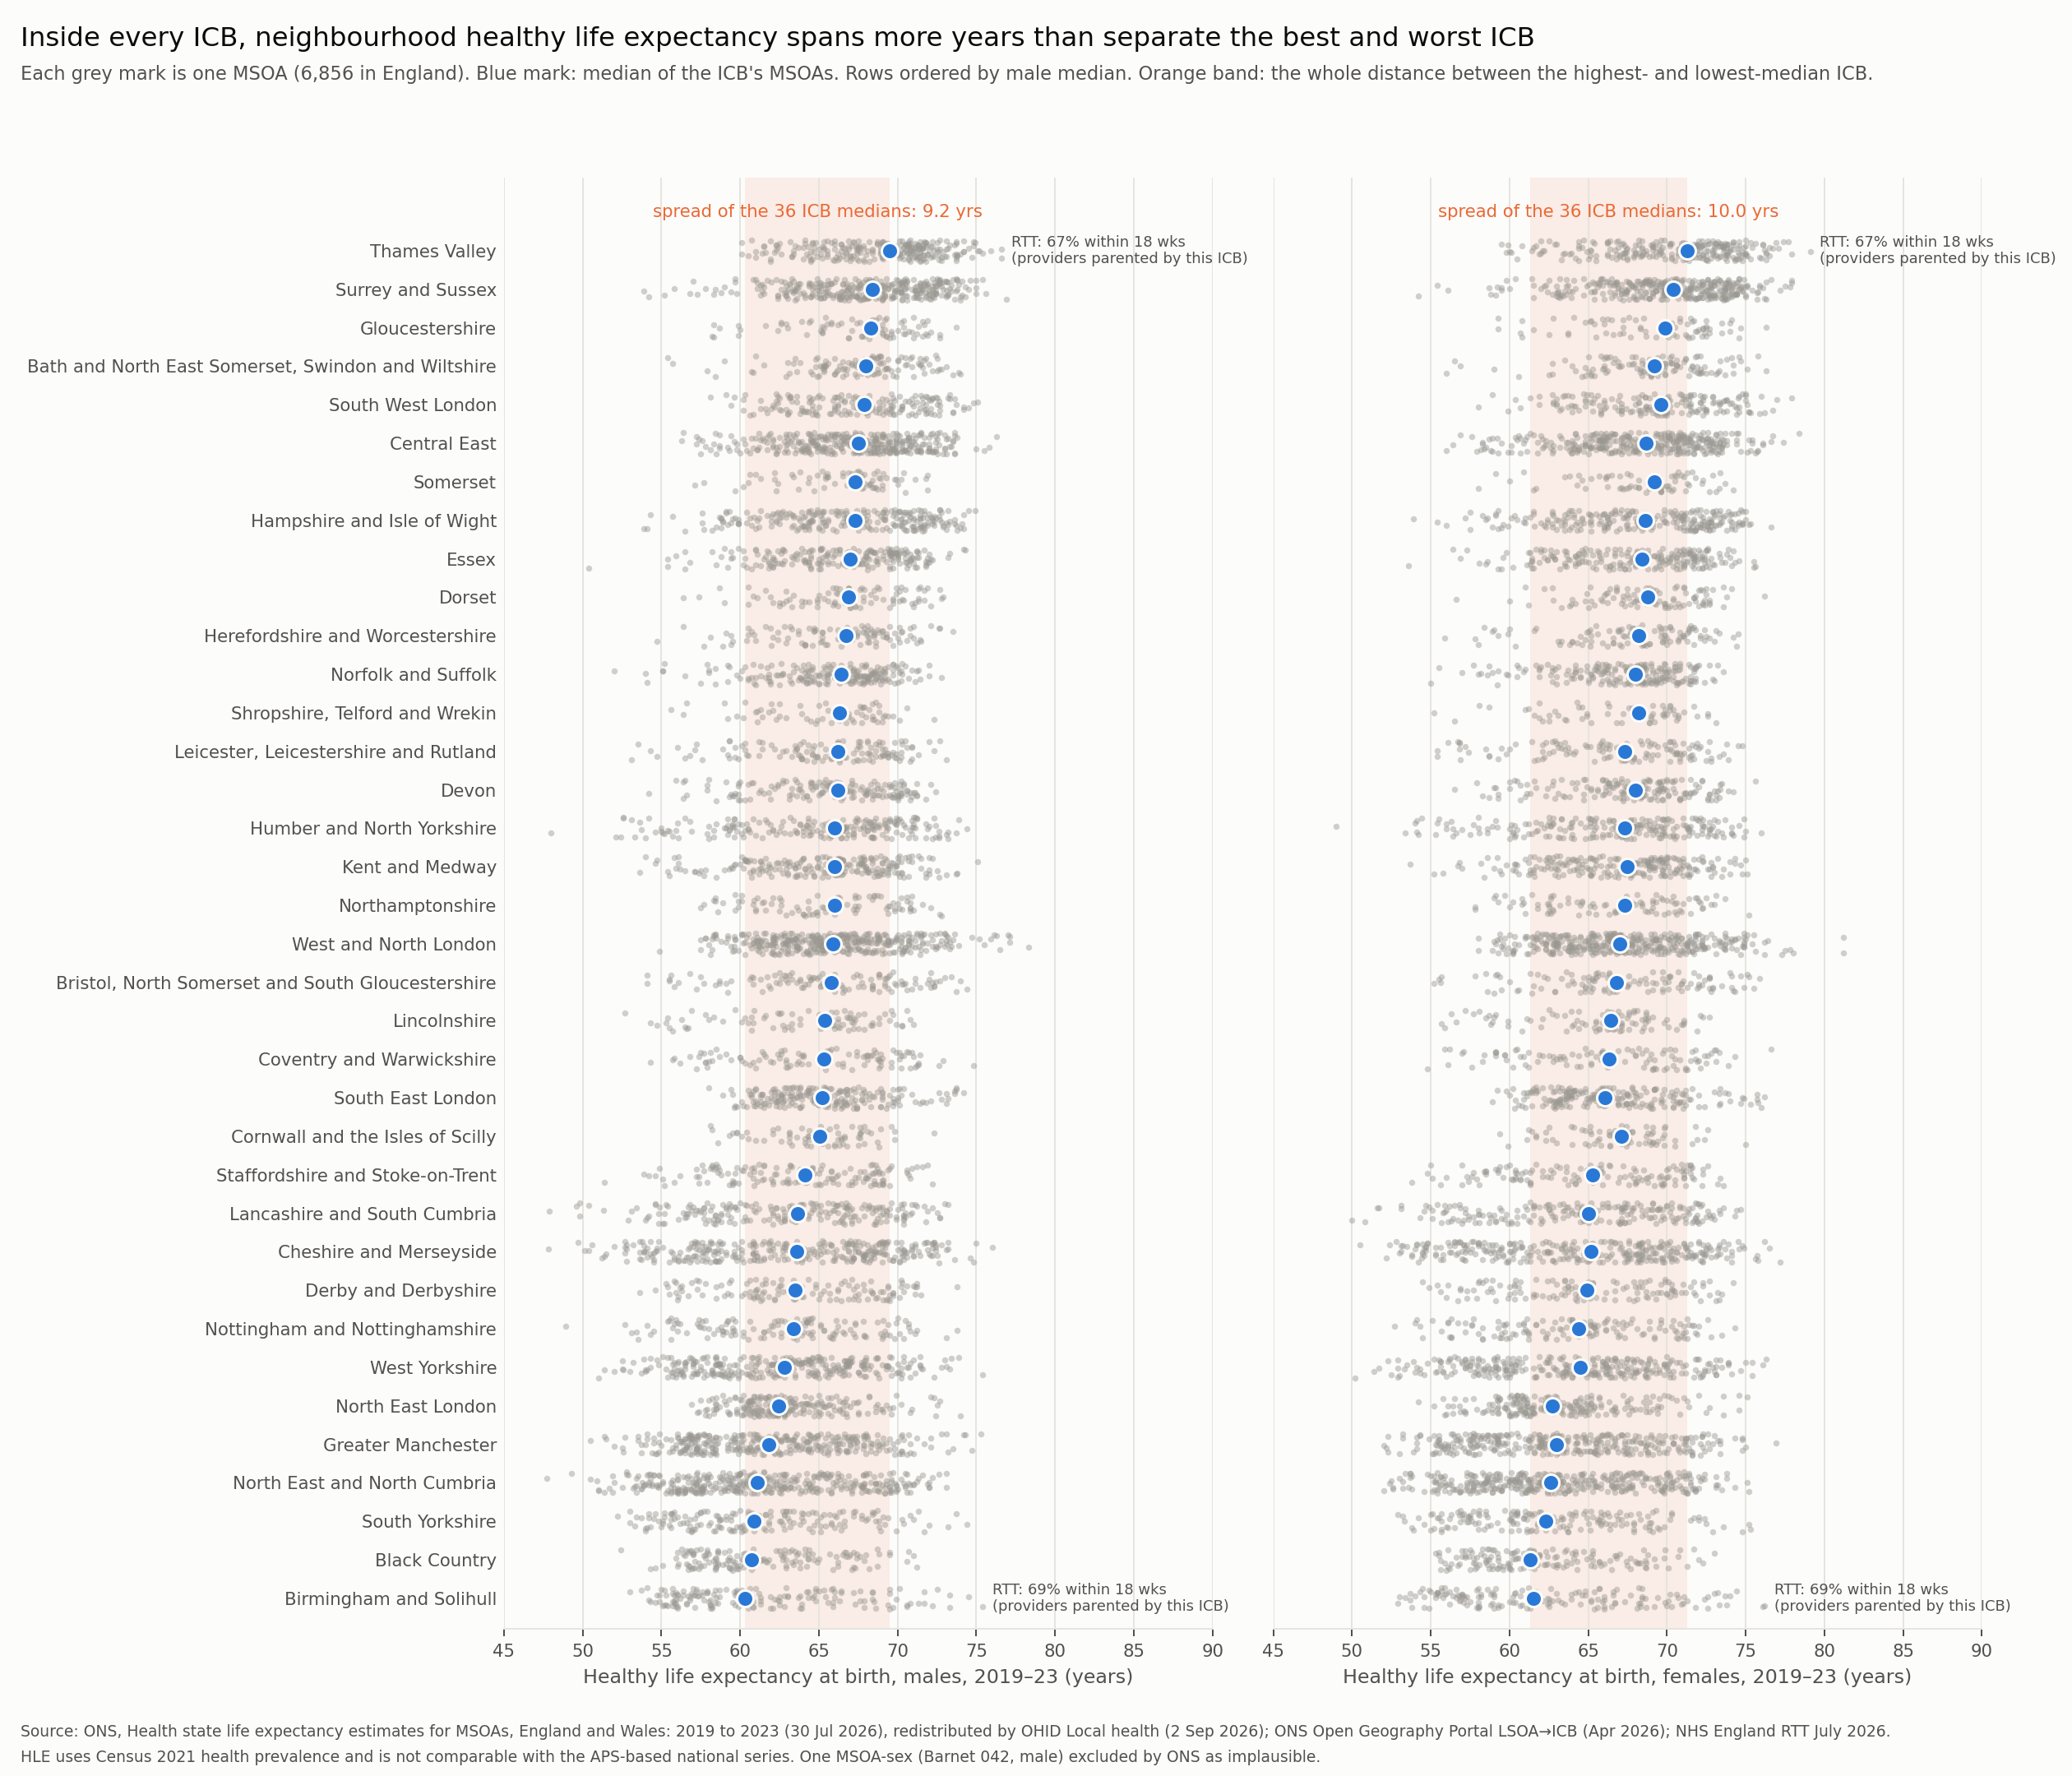

In [10]:
from IPython.display import Image
Image(filename=str(GOLD / "04_chart" / "icb_strip_hle.png"), width=1100)

Every row spills past the orange band on both sides. The two annotated rows —
top and bottom ICB by HLE — carry near-identical 18-week figures, which is the
point.

## What the data cannot say

- HLE 2019–2023 straddles the pandemic; five-year pooling; Census 2021 health prevalence assumed constant.
- Census-based HLE is not comparable with the APS-based national series.
- RTT is one month. Four providers did not submit.
- The crosswalk is admissions, not RTT pathways; acute only; rounded; suppressed under 8.
- No causal claim in either direction.